# Rain rate from Z, KDP and A on S, C and X band

**radar-wow stage 6.** Four relations and one blend:

| algorithm | relation | source |
|---|---|---|
| `ZRRelation` | Z = a R^b | Marshall & Palmer 1948 (200, 1.6); WSR-88D 300, 1.4 with 53 dBZ hail cap (Fulton et al. 1998); Chennai 267, 1.345 (Suresh et al. 2005) |
| `RainRateKDP` | R = c KDP^d | band defaults as documented in Py-ART (S 50.7/0.85, C 29.7/0.85, X 15.81/0.7992) |
| `RainRateA` | R = e A^f | Ryzhkov et al. 2014, Table 1, per band and temperature (10 C row cross-checked with Py-ART) |
| `RainRateZZDR` | R = g Z^h ZDR^k | NEXRAD DP-QPE, S band only |
| `SyntheticRainRate` | per gate: R(KDP) if Z >= 50 dBZ, else R(A), else R(Z) | logic of the MRMS synthetic QPE (Zhang et al. 2020) |

Why R(A) and R(KDP) matter: they do not depend on the radar's Z calibration, on wet-radome loss or
on partial beam blockage. R(Z) does, and it is the only option for reflectivity-only data (today's IMD exports).

In [1]:
# Colab: uncomment to install
!pip install -q "git+https://github.com/radar-wow/radarwow-core" "git+https://github.com/radar-wow/radarwow-kdp" "git+https://github.com/radar-wow/radarwow-attenuation" "git+https://github.com/radar-wow/radarwow-estimation"

zsh:1: command not found: pip


In [2]:
import warnings

warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from radarwow.attenuation import Testud2000ZPHI
from radarwow.attenuation.common import path_dphi, phidp_rec, rain_path
from radarwow.core import load_band, load_sample
from radarwow.core.plotting import ppi
from radarwow.estimation import RainRateZZDR, SyntheticRainRate, coefficients
from radarwow.kdp import Vulpiani2012KDP

FIG = "../docs/figures"

## 1. The relations side by side
Same rain, three different "rulers". Note how R(KDP) and R(A) change with band (the signal grows
with frequency, so the same KDP or A means less rain at X band), while R(Z) does not.

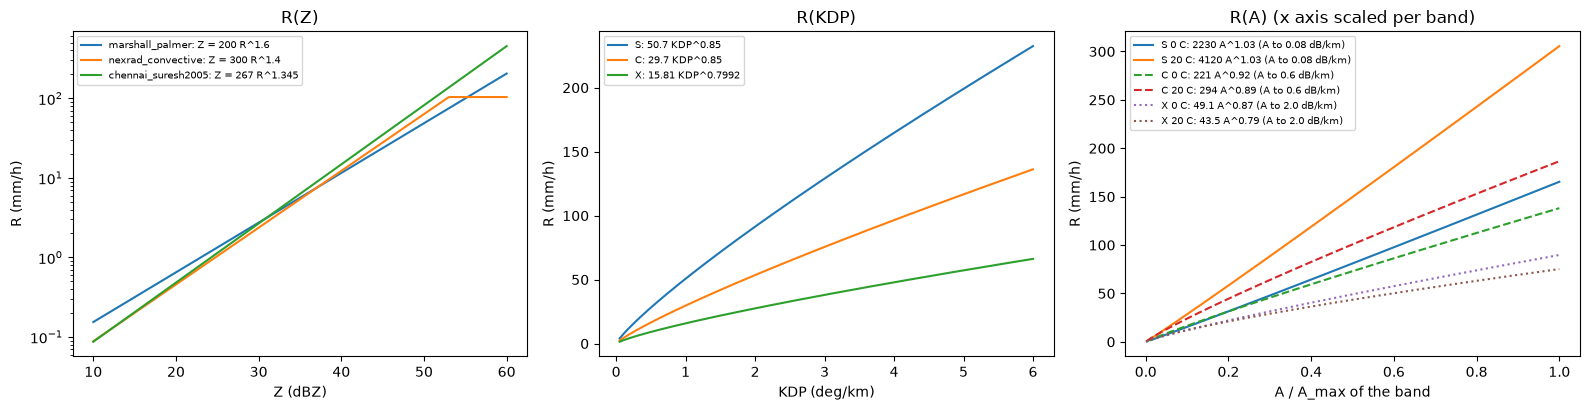

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
zdb = np.linspace(10, 60, 200)
for name, p in coefficients.ZR_PRESETS.items():
    z = np.minimum(zdb, p["z_max_dbz"]) if p["z_max_dbz"] else zdb
    ax[0].plot(zdb, (10 ** (0.1 * z) / p["a"]) ** (1 / p["b"]), label=f"{name}: Z = {p['a']:g} R^{p['b']:g}")
ax[0].set(yscale="log", xlabel="Z (dBZ)", ylabel="R (mm/h)", title="R(Z)")
k = np.linspace(0.05, 6, 200)
for band, p in coefficients.RKDP.items():
    ax[1].plot(k, p["c"] * k ** p["d"], label=f"{band}: {p['c']} KDP^{p['d']}")
ax[1].set(xlabel="KDP (deg/km)", ylabel="R (mm/h)", title="R(KDP)")
for band, ls in zip("SCX", ["-", "--", ":"]):
    amax = {"S": 0.08, "C": 0.6, "X": 2.0}[band]
    a = np.linspace(0.001, amax, 200)
    for t in (0, 20):
        e, f = coefficients.ra_coefficients(band, t)
        ax[2].plot(a / amax, e * a ** f, ls, label=f"{band} {t} C: {e:g} A^{f:g} (A to {amax} dB/km)")
ax[2].set(xlabel="A / A_max of the band", ylabel="R (mm/h)", title="R(A) (x axis scaled per band)")
for a_ in ax:
    a_.legend(fontsize=7)
fig.tight_layout()
fig.savefig(f"{FIG}/01_relations.png", dpi=110)
plt.show()

## 2. One pipeline, three radars
`open_volume` -> `Vulpiani2012KDP` -> `Testud2000ZPHI` (corrected Z, PIA, A_H) -> estimators.
Temperature for R(A) coefficients: 20 C (warm-season convection in all three cases).

In [4]:
samples = {"S": "nexrad_ktlx_s", "C": "arm_csapr2_c", "X": "arm_xsapr_x"}
res, raw = {}, {}
for band, name in samples.items():
    ds = load_sample(name, sweeps=[0])["sweep_0"].to_dataset()
    raw[band] = ds
    att = Testud2000ZPHI()(Vulpiani2012KDP()(ds, band=band), band=band)
    out = SyntheticRainRate(temperature_c=20)(att, band=band)
    if band == "S":
        out = RainRateZZDR()(out, band="S")
    res[band] = out

rows = ["| band | gates with rain | from R(A) | from R(KDP) | from R(Z) | median R (mm/h) | 99th pct | max | gates > 200 mm/h |", "|---|---|---|---|---|---|---|---|---|"]
for band, o in res.items():
    r, s = o["RATE"].values, o["RATE_SOURCE"].values
    n = int(np.isfinite(r).sum())
    rows.append(f"| {band} | {n} | {100 * (s == 1).sum() / n:.0f}% | {100 * (s == 2).sum() / n:.1f}% | {100 * (s == 3).sum() / n:.0f}% | "
                f"{np.nanmedian(r[r > 0.1]):.1f} | {np.nanpercentile(r[r > 0.1], 99):.0f} | {np.nanmax(r):.0f} | {int((r > 200).sum())} |")
display(Markdown("\n".join(rows)))

| band | gates with rain | from R(A) | from R(KDP) | from R(Z) | median R (mm/h) | 99th pct | max | gates > 200 mm/h |
|---|---|---|---|---|---|---|---|---|
| S | 195199 | 13% | 2.0% | 85% | 1.3 | 75 | 559 | 16 |
| C | 178244 | 36% | 1.1% | 63% | 2.1 | 80 | 125 | 0 |
| X | 206671 | 17% | 0.0% | 83% | 0.8 | 31 | 245 | 1 |

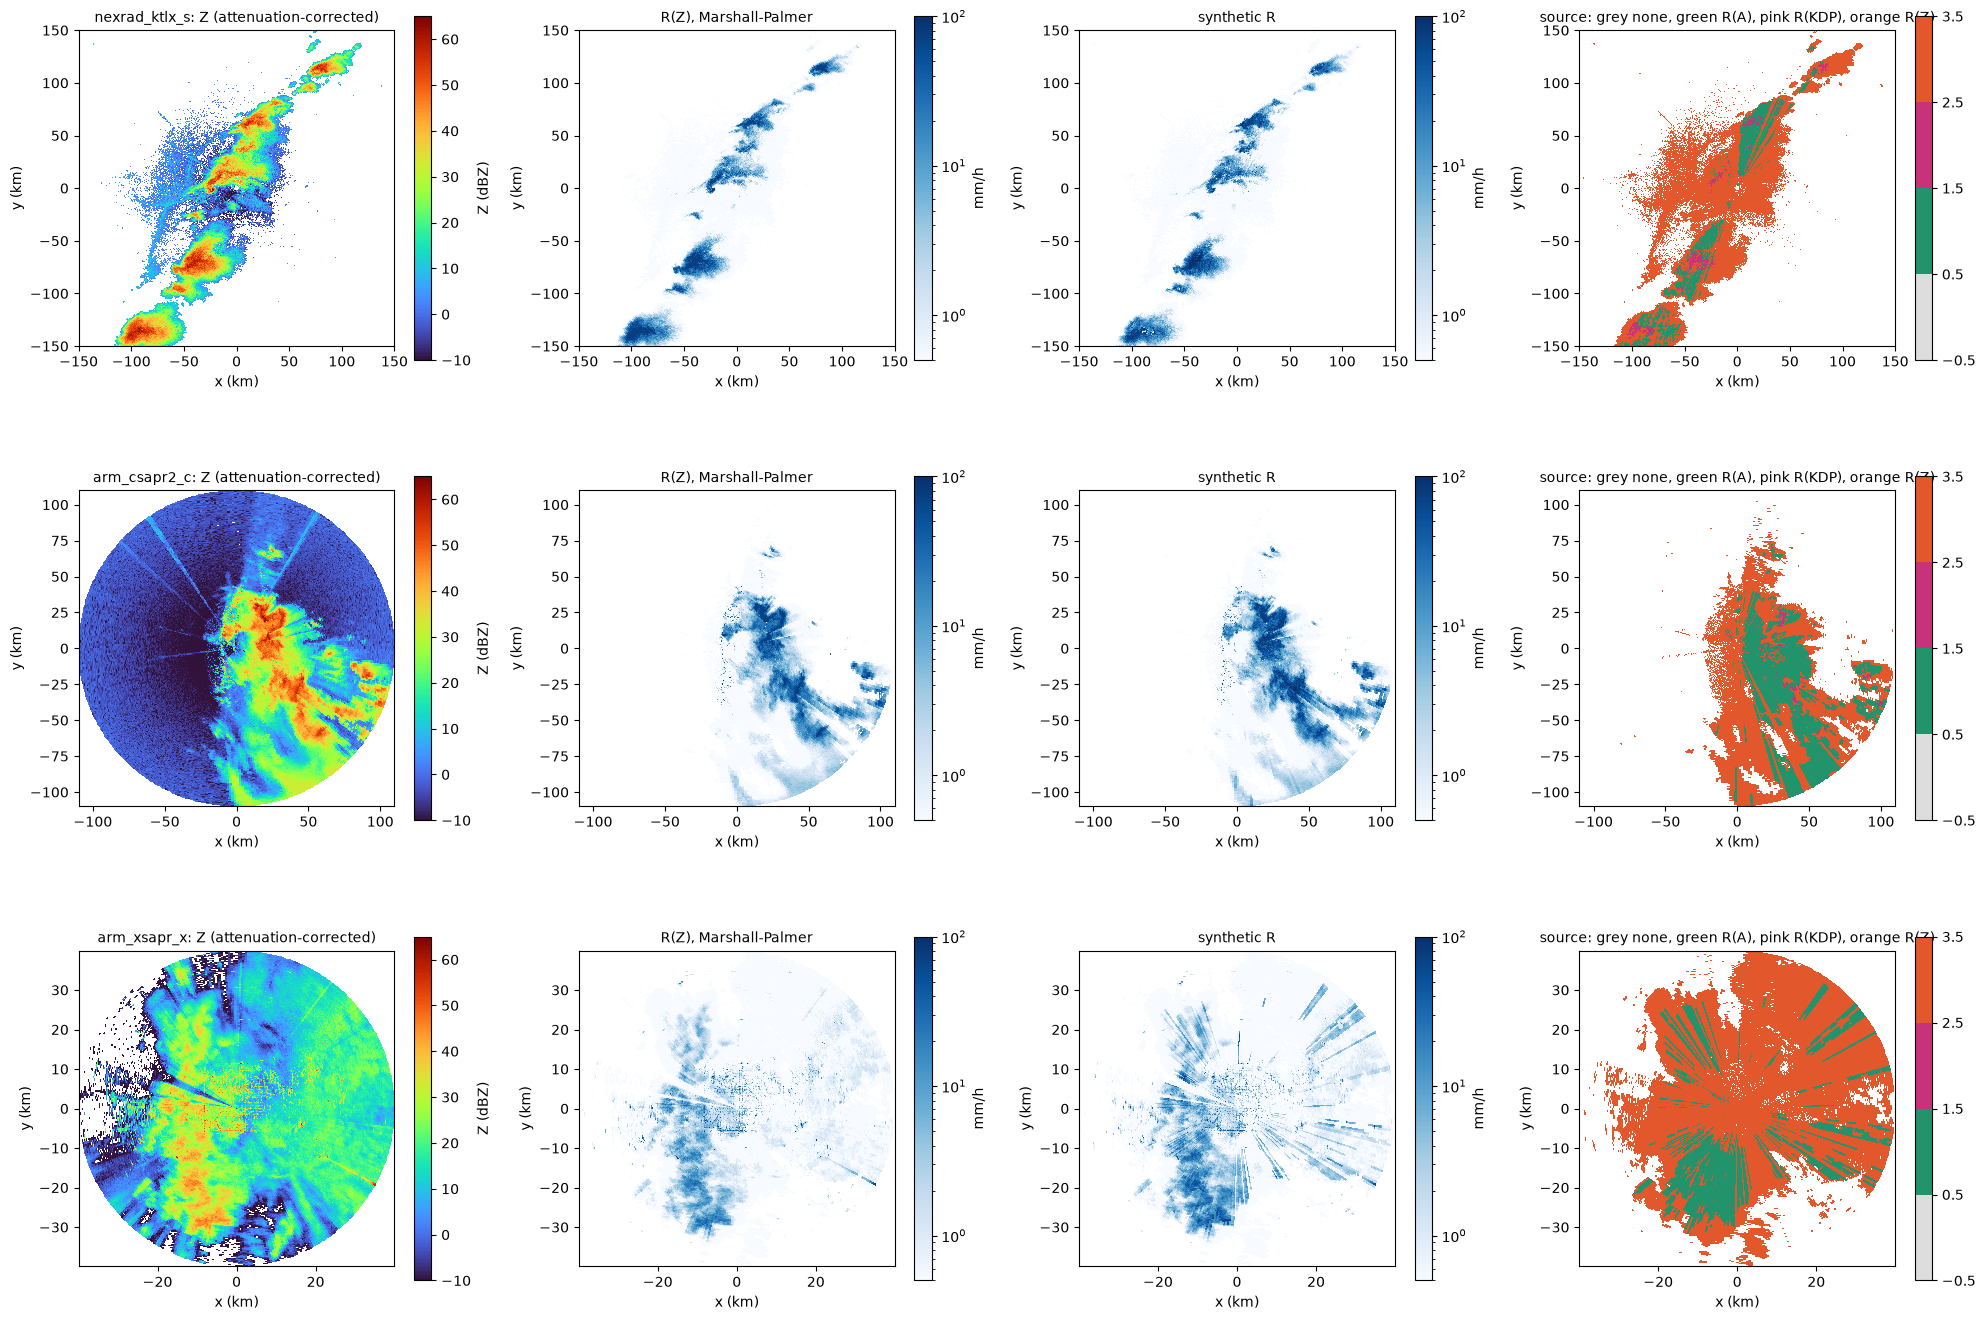

In [5]:
from matplotlib.colors import BoundaryNorm, ListedColormap, LogNorm  # noqa: E402

fig, axes = plt.subplots(3, 4, figsize=(20, 14))
srccmap = ListedColormap(["#dddddd", "#22936a", "#c8327a", "#e2572b"])
for row, (band, o) in enumerate(res.items()):
    km = min(150.0, float(o["range"].values[-1]) / 1e3)
    ppi(o, "DBZH", ax=axes[row, 0], max_km=km, title=f"{samples[band]}: Z (attenuation-corrected)")
    for col, (var, title) in enumerate([("RATE_Z", "R(Z), Marshall-Palmer"), ("RATE", "synthetic R")], start=1):
        ppi(o, var, ax=axes[row, col], max_km=km, title=title, cmap="Blues", norm=LogNorm(0.5, 100), label="mm/h")
    ppi(o.assign(S=o["RATE_SOURCE"].where(np.isfinite(o["RATE"]))), "S", ax=axes[row, 3], max_km=km,
        title="source: grey none, green R(A), pink R(KDP), orange R(Z)", cmap=srccmap, norm=BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], 4), label="")
fig.tight_layout()
fig.savefig(f"{FIG}/02_rain_maps.png", dpi=95)
plt.show()

## 3. Do the estimators agree?
Where two estimators both have a value, their ratio should be near 1 if both are right. R(A) and R(KDP)
do not depend on Z calibration; R(Z) does. A ratio far from 1 that is the same for both R(A)/R(Z) and
R(KDP)/R(Z) points at the Z calibration (or the Z-R choice), not at the polarimetric estimators.

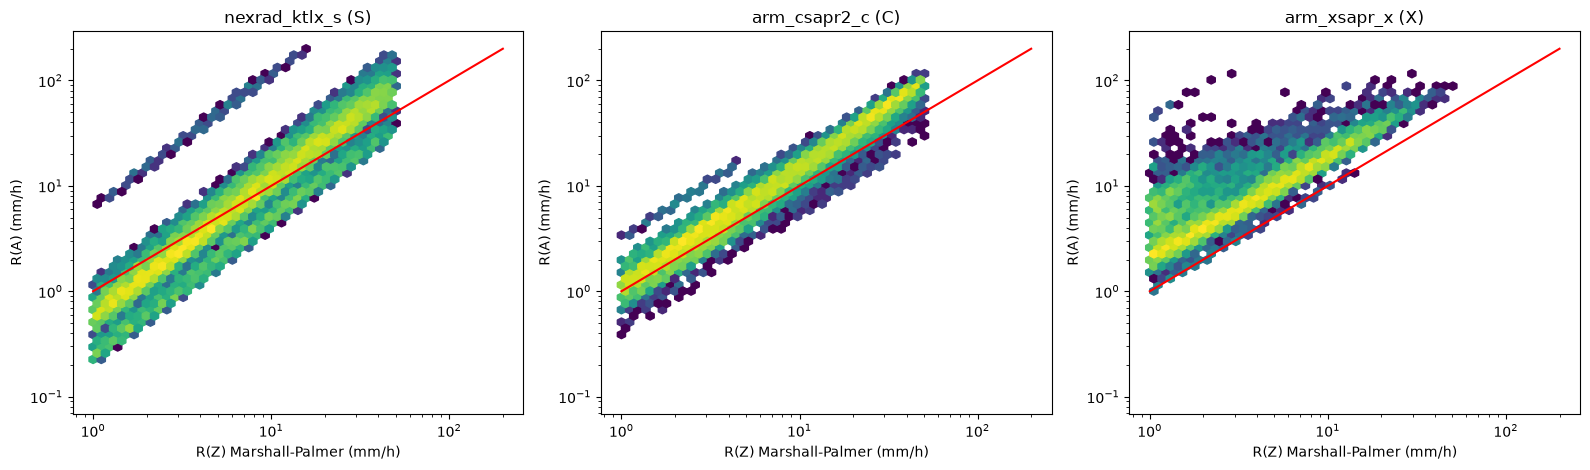

| band | median R(A)/R(Z) | median R(KDP)/R(Z) | median R(A)/R(KDP) | gates |
|---|---|---|---|---|
| S | 0.92 | 2.57 | 0.38 | 19586 |
| C | 1.35 | 2.13 | 0.65 | 50233 |
| X | 2.04 | 2.78 | 0.90 | 18986 |

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
rows = ["| band | median R(A)/R(Z) | median R(KDP)/R(Z) | median R(A)/R(KDP) | gates |", "|---|---|---|---|---|"]
for a_, (band, o) in zip(axes, res.items()):
    ra, rk, rz, z = o["RATE_A"].values, o["RATE_KDP"].values, o["RATE_Z"].values, o["DBZH"].values
    m = np.isfinite(ra) & np.isfinite(rz) & (rz > 1) & (ra > 0.1) & (z < 50)
    mk = m & np.isfinite(rk) & (rk > 1)
    a_.hexbin(rz[m], ra[m], gridsize=50, bins="log", xscale="log", yscale="log", extent=(0, 2.3, -1, 2.3))
    a_.plot([1, 200], [1, 200], "r")
    a_.set(xlabel="R(Z) Marshall-Palmer (mm/h)", ylabel="R(A) (mm/h)", title=f"{samples[band]} ({band})")
    rows.append(f"| {band} | {np.median(ra[m] / rz[m]):.2f} | {np.median(rk[mk] / rz[mk]):.2f} | {np.median(ra[mk] / rk[mk]):.2f} | {m.sum()} |")
fig.tight_layout()
fig.savefig(f"{FIG}/03_ra_vs_rz.png", dpi=110)
plt.show()
display(Markdown("\n".join(rows)))

**Reading the table.**
- R(A) vs R(Z): close at S (0.92) and C (1.35); about 2x at X. Either this X-SAPR's Z reads several dB low,
  or Marshall-Palmer underestimates this convective rain. The calibration stage (self-consistency, GPM
  matching) can tell these apart; until then it is a hypothesis.
- R(KDP) vs R(Z) is 2-3x at *every* band, including S where R(A) agrees with R(Z). That is a selection
  effect, not a calibration signal: we only compare gates with R(KDP) > 1 mm/h, which favours gates where
  KDP noise is positive. R(KDP) is reliable only in heavy rain, which is why the synthetic estimator uses it
  only for Z >= 50 dBZ.

## 4. Where R(A) can and cannot be trusted
Two guards came out of this data, now in the band configs (`ra_min_dphi`, `ra_max_pia`):
1. **Enough total phase shift.** With a small delta PHIDP the attenuation along the ray is too small to
   measure. At S band (A per degree ~5x smaller than at C) R(A) develops a heavy tail below ~40 deg.
2. **Not too much attenuation.** At X band, beyond ~10 dB of PIA, ZPHI amplifies noise near the end of
   the path and A_H jumps to implausible values.

In [7]:
rows = ["| band | ray delta PHIDP (deg) | gates | R(A)/R(Z) median | 99th pct | gates > 10x |", "|---|---|---|---|---|---|"]
for band, ds in raw.items():
    cfg = load_band(band)
    k = Vulpiani2012KDP()(ds, band=band)
    o = SyntheticRainRate(temperature_c=20, )(Testud2000ZPHI()(k, band=band), band=band)
    from radarwow.estimation import RainRateA  # noqa: E402
    unguarded = RainRateA(temperature_c=20, min_dphi=2.0)(Testud2000ZPHI()(k, band=band), band=band)
    _, _, i0, i1 = rain_path(k, cfg)
    dphi = path_dphi(phidp_rec(k, cfg), i0, i1)
    ra, rz, z = unguarded["RATE_A"].values, o["RATE_Z"].values, o["DBZH"].values
    m = np.isfinite(ra) & (rz > 0.1) & (z < 50)
    D = np.repeat(dphi[:, None], ra.shape[1], 1)
    for lo, hi in [(2, 10), (10, 40), (40, 1e9)]:
        mm = m & (D >= lo) & (D < hi)
        if mm.sum():
            q = ra[mm] / rz[mm]
            rows.append(f"| {band} | {lo} to {hi if hi < 1e9 else 'more'} | {mm.sum()} | {np.median(q):.2f} | {np.percentile(q, 99):.1f} | {int((q > 10).sum())} |")
display(Markdown("\n".join(rows)))

| band | ray delta PHIDP (deg) | gates | R(A)/R(Z) median | 99th pct | gates > 10x |
|---|---|---|---|---|---|
| S | 2 to 10 | 6606 | 1.30 | 195.0 | 1207 |
| S | 10 to 40 | 28777 | 0.98 | 57.6 | 997 |
| S | 40 to more | 25276 | 0.77 | 3.8 | 86 |
| C | 2 to 10 | 16808 | 0.86 | 3.7 | 76 |
| C | 10 to 40 | 13624 | 1.12 | 3.3 | 0 |
| C | 40 to more | 40608 | 1.37 | 2.1 | 0 |
| X | 2 to 10 | 26491 | 4.01 | 22.6 | 2964 |
| X | 10 to 40 | 21003 | 2.11 | 25.4 | 1086 |
| X | 40 to more | 932 | 2.47 | 8.5 | 0 |

## 5. Against ARM's own processing (C and X band)
The ARM files carry their own specific attenuation and an R(A). Their CSAPR2 rain rate uses
R = 51.3 A^0.81 (from the file's metadata), very different from Ryzhkov et al. 2014's C-band relation, so
we compare specific attenuation itself, not rain rate.

In [8]:
rows = ["| band | gates | correlation | median ours / ARM |", "|---|---|---|---|"]
for band in ("C", "X"):
    ref, ah = raw[band]["specific_attenuation"].values, res[band]["AH"].values
    m = np.isfinite(ref) & np.isfinite(ah) & (ref > 0.01)
    rows.append(f"| {band} | {m.sum()} | {np.corrcoef(ref[m], ah[m])[0, 1]:.2f} | {np.median(ah[m] / ref[m]):.2f} |")
display(Markdown("\n".join(rows)))

| band | gates | correlation | median ours / ARM |
|---|---|---|---|
| C | 19936 | 0.72 | 2.82 |
| X | 44939 | 0.56 | 0.62 |

## Takeaways
- One synthetic estimator runs on all three bands with the same code; only the band config and the
  coefficient tables change. Reflectivity-only data (IMD today) falls back to R(Z) automatically.
- R(A) is the main estimator in pure rain, but needs two guards that were not in the papers' summaries:
  enough total phase shift (40 deg at S, 5 deg at C and X) and not too much path attenuation (10-20 dB).
- Hail: R(Z) is capped at 53 dBZ (WSR-88D practice); R(KDP) is used where Z >= 50 dBZ and KDP exists.
- X-SAPR: R(A) exceeds R(Z) by ~2x, a hint of low Z calibration (or an unsuited Z-R) to test in stage 1.
- R(KDP) in light and moderate rain is biased by noise; keep it for heavy rain.
- Visible artifact at X band: radial spokes in the synthetic map, where whole rays switch from R(Z) to R(A)
  and the two differ by 2-4x. MRMS smooths such edges with a blending zone (not implemented). The better fix is
  upstream: use R(A) to estimate the Z miscalibration (Diederich et al. 2015, doi:10.1175/JHM-D-14-0066.1),
  which removes the mismatch itself. That belongs to the calibration stage.
- No gauges yet: these are consistency checks, not verification. Next: accumulation and comparison with an
  independent gauge-corrected product (MRMS) on a NEXRAD case, then the melting layer from QVPs.